# 02. Inspection of Training, Model Selection, and Validation Inference Workflow

## Purpose
This notebook inspects the existing training, causal feature engineering, and model-selection workflow of ACPDAD, and demonstrates validation inference on a sample mission. It does not train new models, but rather inspects the pre-trained primary and fallback model artifacts and executes the inference pipeline against saved validation data. It examines the two-tier detection architecture:
1. **Primary Classifier**: A gradient-boosted decision tree ensemble consuming 88 causal temporal features derived over a sliding history window ($W = 10$).
2. **Selected Base Fallback Classifier**: A dedicated classifier consuming the 22 base features to provide continuous detection when history is insufficient ($W < 10$).

> **Evaluation and Preservation Protocols**  
> - Models were trained **strictly on the training split** (`data/train_validation` where `split == 'train'`).
> - The validation split (`split == 'val'`) and development conditions were used exclusively for model selection, threshold tuning, and alert policy calibration.
> - The frozen test set (`data/frozen_test/`, `results/frozen_test/`) is strictly sequestered and not accessed here.
> - Demonstration runs write only to a notebook-specific directory (`results/notebooks/`), preserving the selected model checkpoint and selection records byte-for-byte.
> - All results represent **simulated research**; no real-world or SITL claims are made.

In [1]:
import os
import sys
import json
import pickle
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure root directory and src in sys.path
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

from acpdad.simulation import BASE, TEMPORAL, W, CLASSES
from acpdad.workflow import load_checkpoint, load_dataset, build_views

MODEL_DIR = Path('models/selected')
MANIFEST_PATH = MODEL_DIR / 'manifest.json'

with open(MANIFEST_PATH) as f:
    manifest = json.load(f)

print("Model Status: Verified Selected Checkpoint")
print(f"Selected Fallback Strategy: {manifest.get('fallback_model')}")
print(f"Base Features Count: {manifest.get('base_features')}")
print(f"Temporal Features Count: {manifest.get('temporal_features')}")
print(f"Primary Threshold: {manifest.get('primary_threshold')}")
print(f"Fallback Threshold: {manifest.get('fallback_threshold')}")
print(f"Alert Policy: {manifest.get('alert_policy')}")

Model Status: Verified Selected Checkpoint
Selected Fallback Strategy: base
Base Features Count: 22
Temporal Features Count: 88
Primary Threshold: 0.21
Fallback Threshold: 0.1
Alert Policy: {'alert_k': 4, 'alert_n': 6, 'evidence_expiry_s': 0.8, 'clear_benign_predictions': 3, 'physics_threshold': 0.010762422533106636, 'max_ev_evidence_age_s': 0.35}

## Causal Temporal Feature Engineering (22 Base $\rightarrow$ 88 Temporal)
The primary detector cannot rely on static single-packet snapshots because cyber-physical attacks exhibit dynamic temporal signatures:
- **Base Features (22)**: Current state $x_t$.
- **Window Mean (22)**: Moving average $\bar{x}_{t, W=10} = \frac{1}{10}\sum_{i=0}^9 x_{t-i}$.
- **Window Standard Deviation (22)**: Moving sample standard deviation $s_{t, W=10}$.
- **One-Step Difference (22)**: Rate of change $\Delta x_t = x_t - x_{t-1}$.

Total: $22 + 22 + 22 + 22 = 88$ features.
All temporal statistics are computed **strictly forward in arrival time**. Any packet arriving out of order is rejected, and any transmission gap $> 1.0$s triggers a window reset to prevent cross-gap temporal leakage.

In [2]:
print(f"Window Size W: {W} observations")
print(f"Base Features Count: {len(BASE)}")
print(f"Temporal Features Count: {len(TEMPORAL)}")

# Display breakdown of temporal feature suffixes
suffixes = {col.split('_')[-1] for col in TEMPORAL if '_' in col}
print(f"Temporal Suffix Categories: {sorted(list(suffixes))}")

# Verify exact column match with schema
with open('data/train_validation/schema.json') as f:
    schema = json.load(f)
assert schema['temporal_features'] == TEMPORAL
print("Temporal features match schema contract exactly.")

Window Size W: 10 observations
Base Features Count: 22
Temporal Features Count: 88
Temporal Suffix Categories: ['10', 'changed', 'cm', 'deg', 'diff', 'frame', 'gap', 'length', 'm', 'mps', 'payload', 'pps', 'regression', 's']
Temporal features match schema contract exactly.

## The Fallback Model Problem and Solution
When a mission begins, observations 1 through 9 cannot construct a full 10-observation sliding window ($W < 10$). Similarly, after a network gap or buffer reset, the window is emptied.
- In earlier system revisions, this caused an unavoidable **warmup blind spot** where no predictions could be emitted.
- In ACPDAD, a two-tier causal fallback mechanism is employed:
  - When $W \ge 10$: The **Primary Classifier** (88 features) is executed.
  - When $W < 10$: The **Fallback Classifier** (22 base features) is invoked.
- During validation, candidate fallback architectures (`base` 22-feature vs `short3` 3-observation window) were benchmarked. The 22-base feature model was selected for superior reliability and zero warmup requirement.

In [3]:
# Load the selected checkpoint using the existing workflow loader
checkpoint = load_checkpoint(MODEL_DIR)

models = checkpoint['models']
print("Loaded Checkpoint Estimators:")
for name, estimator in models.items():
    print(f"  - {name}: {type(estimator).__name__} (classes: {estimator.classes_})")

print(f"\nSelected Fallback: '{checkpoint['fallback_selected']}'")
print(f"Primary Evil_Twin Threshold: {checkpoint['primary_threshold']}")
print(f"Fallback Evil_Twin Threshold: {checkpoint['fallback_threshold']}")

Loaded Checkpoint Estimators:
  - primary: HistGradientBoostingClassifier (classes: ['Benign' 'DoS' 'Evil_Twin' 'FDI' 'Replay'])
  - fallback_base: HistGradientBoostingClassifier (classes: ['Benign' 'DoS' 'Evil_Twin' 'FDI' 'Replay'])
  - fallback_short3: HistGradientBoostingClassifier (classes: ['Benign' 'DoS' 'Evil_Twin' 'FDI' 'Replay'])

Selected Fallback: 'base'
Primary Evil_Twin Threshold: 0.21
Fallback Evil_Twin Threshold: 0.1

## Validation Selection & Alert Policy Calibration
The raw classifier probabilities are not emitted directly as alarms. Instead, an alert confirmation policy is calibrated on development validation runs:
1. **$K$-of-$N$ Confirmation**: Requires $K = 4$ non-Benign predictions within a sliding window of $N = 6$ timely predictions to raise an alert.
2. **Benign Hysteresis**: Requires 3 consecutive Benign predictions to clear an active alert.
3. **Evidence Expiry**: An active alert automatically expires after $0.8$s if no fresh timely evidence arrives.
4. **Evil_Twin Source Age Constraint**: Evil_Twin alerts require source evidence age $\le 0.35$s to prevent stale replay frames from masquerading as fresh rogue AP attacks.
5. **Decoupled Physics Warnings**: Vertical kinematic residual $> 0.0108$m triggers an independent warning; it does not automatically raise a cyber alert.

In [4]:
selection_path = Path('results/selection/training/validation_selection.json')
with open(selection_path) as f:
    selection = json.load(f)

print(f"Training Runs: {selection['train_run_count']}")
print(f"Validation Runs: {selection['validation_run_count']}")
print(f"Primary Model: {selection['primary_model']}")
print(f"Fallback Model: {selection['fallback_model']}")
print(f"Validation Alert Acceptance Met: {selection['alert_acceptance_met_in_validation']}")
print(f"Validation Metrics Summary:")
for k, v in selection['validation_selected_metrics'].items():
    if not isinstance(v, (dict, list)):
        print(f"  {k}: {v}")

Training Runs: 200
Validation Runs: 100
Primary Model: HistGradientBoostingClassifier
Fallback Model: HistGradientBoostingClassifier
Validation Alert Acceptance Met: False
Validation Metrics Summary:
  mean_condition_benign_alert_mission_rate: 0.1861111111111111
  mean_condition_false_episodes_per_minute: 0.43333333333333335
  mean_condition_pre_attack_rate: 0.09166666666666667
  mean_condition_attack_alert_rate: 1.0
  mean_condition_end_to_end_recall: 0.860926809843463
  mean_condition_attack_alert_delay_s: 1.370684766211111
  premature_alert_acceptance_met_on_validation: False

## Validation Inference Demonstration on a Selected Mission
We now demonstrate the end-to-end inference workflow by executing validation inference on a selected validation mission.
To protect the existing project:
- Outputs are saved strictly to `results/notebooks/reproduction_run/`.
- The selected checkpoint (`models/selected/checkpoint.pkl`) and selection records (`results/selection/`) remain untouched.

In [5]:
from acpdad.workflow import predict_cli
import re

REPRO_OUTPUT = Path("results/notebooks/reproduction_run")
REPRO_OUTPUT.mkdir(parents=True, exist_ok=True)
output_csv = REPRO_OUTPUT / "validation_run_predictions.csv"

# Remove existing file if re-running
if output_csv.exists():
    output_csv.unlink()

# Select a validation sample run dynamically from canonical manifest
manifest = pd.read_csv("data/train_validation/run_manifest.csv")
sample_canonical_id = manifest[manifest["split"] == "val"].query("scenario == 'Evil_Twin'").iloc[0]["run_id"]

result = predict_cli(
    data="data/train_validation",
    model_dir="models/selected",
    output=output_csv,
    run_id=sample_canonical_id,
    run_alias="validation_run_001",
)

print(f"Reproduction Prediction Status: {result['status']}")
print(f"Delivered Packets: {result['delivered_packets']}")
print(f"Prediction Rows Emitted: {result['prediction_rows']}")
print(f"Saved Output: {result['output']}")


Reproduction Prediction Status: passed
Delivered Packets: 257
Prediction Rows Emitted: 257
Saved Output: results/notebooks/reproduction_run/validation_run_predictions.csv


## Visualizing the Prediction Timeline and Fallback Switching
Let us load the generated predictions and examine how the detector seamlessly switches from the 22-feature fallback model during the first 9 observations to the 88-feature primary model thereafter.

<string>:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown

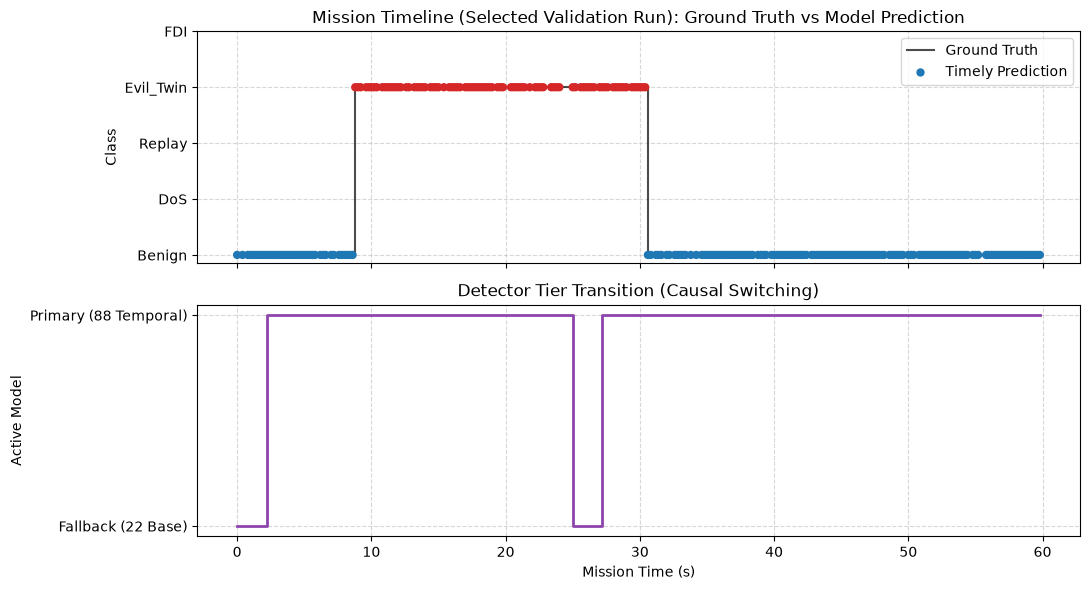

In [6]:
pred_df = pd.read_csv(output_csv)

# Load ground truth for this run to compare
truth = pd.read_csv("data/train_validation/ground_truth.csv")
run_truth = truth[truth["run_id"] == sample_canonical_id].sort_values("sample_index").copy()
run_truth["run_id"] = "validation_run_001"
run_truth["observation_id"] = run_truth["observation_id"].str.replace(f"^{re.escape(sample_canonical_id)}", "validation_run_001", regex=True)

# Merge Target_Label onto predictions
merged = pred_df.merge(run_truth[["observation_id", "Target_Label"]], on="observation_id", how="left")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)

class_to_idx = {c: i for i, c in enumerate(CLASSES)}

# Top plot: Scheduled Ground Truth vs Model Prediction
ax1.step(merged["sample_index"] * 0.2, merged["Target_Label"].map(class_to_idx), 
         where="post", label="Ground Truth", color="black", linewidth=1.5, alpha=0.7)

# Scatter timely predictions
timely = merged[merged["timely"] == True]
colors = [plt.cm.tab10(class_to_idx[p]) for p in timely["prediction"]]
ax1.scatter(timely["sample_index"] * 0.2, timely["prediction"].map(class_to_idx), 
            c=colors, s=25, label="Timely Prediction", zorder=3)

ax1.set_yticks(range(len(CLASSES)))
ax1.set_yticklabels(CLASSES)
ax1.set_ylabel("Class")
ax1.set_title("Mission Timeline (Validation Run 001): Ground Truth vs Model Prediction")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

# Bottom plot: Model Source (Fallback vs Primary)
model_source_num = timely["selected_model"].map(lambda x: 1 if x == "primary_temporal" else 0)
ax2.step(timely["sample_index"] * 0.2, model_source_num, where="post", color="#8e44ad", linewidth=2)
ax2.set_yticks([0, 1])
ax2.set_yticklabels(["Fallback (22 Base)", "Primary (88 Temporal)"])
ax2.set_xlabel("Mission Time (s)")
ax2.set_ylabel("Active Model")
ax2.set_title("Detector Tier Transition (Causal Switching)")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


## Conclusion
- **Continuous Coverage**: The 22-base feature fallback model eliminates the warmup latency gap, providing immediate protection from observation 0.
- **Causal Integrity**: Feature expansion and state transitions preserve strict causality without lookahead, out-of-order contamination, or gap bleeding.
- **Workflow Isolation**: The selected model checkpoint and selection records remain verified and untouched, with all demonstration outputs isolated to `results/notebooks/`.